<a href="https://colab.research.google.com/github/julia-zhmurko/JuliaZhmurko-ML/blob/main/%D0%9B%D0%B0%D0%B1%D0%BE%D1%80%D0%B0%D1%82%D0%BE%D1%80%D0%BD%D1%96_%D1%80%D0%BE%D0%B1%D0%BE%D1%82%D0%B8/%D0%96%D0%BC%D1%83%D1%80%D0%BA%D0%BE_%D0%AE%D0%BB%D1%96%D1%8F_%D0%A4%D0%86%D0%A2_4_10_%D0%9B%D0%A0_10_%D0%9C%D0%9D_%D0%9A%D0%B5%D1%80%D0%B0%D1%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  

**Прізвище, ім’я:** Жмурко Юлія Андріївна

**Група:** ФІТ 4-10  

**Дата:** 25.11.2026

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

**Виконала:** студентка групи ФІТ 4-10 Жмурко Юлія Андріївна

**Була присутня на парі (25.11.2026)**

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [14]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import os

from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report

keras.utils.set_random_seed(42)

print("Необхідні бібліотеки успішно підключено!")
print(f"Версія TensorFlow: {tf.__version__}")
print(f"Версія Keras: {keras.__version__}")
print(f"Версія NumPy: {np.__version__}")
print(f"Наявність GPU: {'Так' if tf.config.list_physical_devices('GPU') else 'Ні'}")
print("Фіксоване значення random seed: 42")

Необхідні бібліотеки успішно підключено!
Версія TensorFlow: 2.21.0
Версія Keras: 3.13.2
Версія NumPy: 2.4.6
Наявність GPU: Ні
Фіксоване значення random seed: 42


###**Пояснення:**

Підключено необхідні бібліотеки та компоненти для подальшої роботи з набором даних `Fashion MNIST`, побудови, навчання й оцінювання якості нейронної мережі:

- `NumPy` — для роботи з багатовимірними масивами та виконання числових операцій;

- `Matplotlib` — для візуалізації зображень, побудови графіків та представлення результатів навчання;

- `TensorFlow` та `Keras` — для побудови, навчання й оцінювання нейронних мереж;

- `os` — для роботи з файловою системою, файлами та каталогами;

- `layers` та `models` — для створення шарів і формування архітектури нейронної мережі;

- `EarlyStopping` — для дострокового припинення навчання за відсутності покращення контрольованого показника;

- `ReduceLROnPlateau` — для автоматичного зменшення швидкості навчання за відсутності покращення контрольованого показника;

- `classification_report` — для формування звіту про якість класифікації за метриками `Precision`, `Recall` та `F1-score`.

Для підвищення відтворюваності результатів навчання встановлено фіксоване початкове значення генераторів випадкових чисел (`random seed = 42`).

# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [15]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:

(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    "Футболка / топ",
    "Штани",
    "Пуловер",
    "Сукня",
    "Пальто",
    "Сандалі",
    "Сорочка",
    "Кросівки",
    "Сумка",
    "Ботильйони"
]

print("Розміри масивів навчальної вибірки:")
print(f"x_train: {x_train.shape}")
print(f"y_train: {y_train.shape}")

print("\nРозміри масивів тестової вибірки:")
print(f"x_test: {x_test.shape}")
print(f"y_test: {y_test.shape}")

print(f"\nЗагальна кількість зображень: {len(x_train) + len(x_test)}")
print(f"Кількість навчальних зображень: {len(x_train)}")
print(f"Кількість тестових зображень: {len(x_test)}")
print(f"Розмір одного зображення: {x_train.shape[1]} × {x_train.shape[2]} пікселів")
print(f"Кількість класів: {len(class_names)}")

print("\nПерелік класів Fashion MNIST:")
for i, class_name in enumerate(class_names):
    print(f"{i} — {class_name}")

Розміри масивів навчальної вибірки:
x_train: (60000, 28, 28)
y_train: (60000,)

Розміри масивів тестової вибірки:
x_test: (10000, 28, 28)
y_test: (10000,)

Загальна кількість зображень: 70000
Кількість навчальних зображень: 60000
Кількість тестових зображень: 10000
Розмір одного зображення: 28 × 28 пікселів
Кількість класів: 10

Перелік класів Fashion MNIST:
0 — Футболка / топ
1 — Штани
2 — Пуловер
3 — Сукня
4 — Пальто
5 — Сандалі
6 — Сорочка
7 — Кросівки
8 — Сумка
9 — Ботильйони


###**Пояснення:**

Завантажено набір даних `Fashion MNIST` за допомогою функції `keras.datasets.fashion_mnist.load_data()`, яка повертає попередньо сформовані навчальну та тестову вибірки. Набір даних призначений для розв’язування задачі багатокласової класифікації зображень предметів одягу, взуття та аксесуарів.

У результаті завантаження отримано чотири масиви:

- `x_train` — масив зображень навчальної вибірки розмірністю (60000, 28, 28);

- `y_train` — масив міток класів навчальної вибірки розмірністю (60000,);

- `x_test` — масив зображень тестової вибірки розмірністю (10000, 28, 28);

- `y_test` — масив міток класів тестової вибірки розмірністю (10000,).

Визначено список `class_names`, який містить назви 10 класів українською мовою: футболка / топ, штани, пуловер, сукня, пальто, сандалі, сорочка, кросівки, сумка та ботильйони. Кожному класу відповідає числова мітка від 0 до 9. Сформований список надалі використовуватиметься для наочного представлення зображень та інтерпретації результатів класифікації.

Набір даних `Fashion MNIST` містить 70 000 зображень, з яких 60 000 належать до початкової навчальної вибірки та 10 000 — до тестової. Кожне зображення представлене у відтінках сірого та має розмір 28 × 28 пікселів, тобто містить 784 пікселі. Кожному зображенню відповідає одна мітка класу.

### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

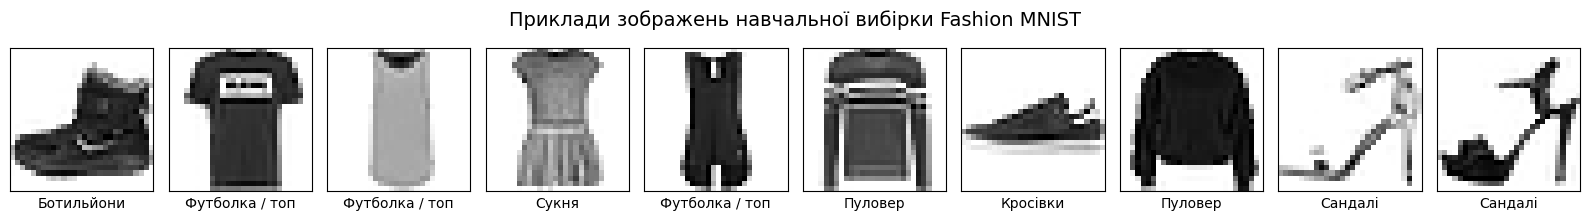

In [16]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:

plt.figure(figsize = (16, 2.2))

for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(x_train[i], cmap = "gray_r")
    plt.xlabel(class_names[y_train[i]], fontsize = 10)
    plt.xticks([])
    plt.yticks([])

plt.suptitle("Приклади зображень навчальної вибірки Fashion MNIST", fontsize = 14, y = 0.92)
plt.tight_layout()
plt.show()

###**Пояснення:**

Виконано візуальний аналіз набору даних `Fashion MNIST` шляхом відображення перших 10 зображень навчальної вибірки (`x_train`) із зазначенням відповідних назв класів. Для побудови візуалізації використано бібліотеку `Matplotlib`.

За допомогою функції `plt.subplot()` сформовано область відображення, яка складається з одного рядка та десяти стовпців. Для відображення зображень використано функцію `plt.imshow()` з параметром `cmap = "gray_r"`, що забезпечує представлення предметів у відтінках сірого на білому тлі. Під кожним зображенням виведено назву відповідного класу українською мовою шляхом зіставлення числової мітки з масиву `y_train` з елементом списку `class_names`. Для покращення наочності приховано поділки координатних осей, додано загальний заголовок та автоматично налаштовано розташування елементів візуалізації.

Отримано 10 зображень навчальної вибірки, серед яких представлено:

- ботильйони — 1 зображення;
- футболка / топ — 3 зображення;
- сукня — 1 зображення;
- пуловер — 2 зображення;
- кросівки — 1 зображення;
- сандалі — 2 зображення.

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [17]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:

print("До нормалізації:")

print(f"Навчальна вибірка: [{x_train.min()}; {x_train.max()}]")
print(f"Тип даних x_train: {x_train.dtype}")

print(f"Тестова вибірка: [{x_test.min()}; {x_test.max()}]")
print(f"Тип даних x_test: {x_test.dtype}")

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("\nПісля нормалізації:")

print(f"Навчальна вибірка: [{x_train.min()}; {x_train.max()}]")
print(f"Тип даних x_train: {x_train.dtype}")

print(f"Тестова вибірка: [{x_test.min()}; {x_test.max()}]")
print(f"Тип даних x_test: {x_test.dtype}")

До нормалізації:
Навчальна вибірка: [0; 255]
Тип даних x_train: uint8
Тестова вибірка: [0; 255]
Тип даних x_test: uint8

Після нормалізації:
Навчальна вибірка: [0.0; 1.0]
Тип даних x_train: float32
Тестова вибірка: [0.0; 1.0]
Тип даних x_test: float32


###**Пояснення:**

Виконано нормалізацію значень пікселів зображень навчальної (`x_train`) та тестової (`x_test`) вибірок набору даних `Fashion MNIST`. Перед нормалізацією за допомогою методів `min()` та `max()` визначено мінімальні й максимальні значення пікселів, а за допомогою атрибута `dtype` — тип даних відповідних масивів.

Для приведення значень пікселів до діапазону [0; 1] виконано перетворення типу даних на `float32` за допомогою методу `astype()` та ділення кожного значення пікселя на 255. Нормалізацію здійснено за формулою:

**xnorm = x / 255**,

де **x** - початкове значення пікселя, **xnorm** - нормалізоване значення пікселя.

Отримані результати підтверджують коректність виконання нормалізації: значення пікселів обох вибірок приведено до діапазону [0; 1], а тип даних змінено з цілочисельного беззнакового 8-бітного (`uint8`) на дійсний 32-бітний (`float32`), придатний для навчання нейронної мережі. При цьому розмірність масивів зображень та мітки відповідних класів (`y_train` і `y_test`) залишилися незмінними.

### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [18]:
# Створіть і скомпілюйте модель.
# Ваш код:

model = models.Sequential([
    layers.Input(shape = (28, 28)),
    layers.Flatten(),

    layers.Dense(256, activation = "relu"),
    layers.Dropout(0.3),

    layers.Dense(128, activation = "relu"),
    layers.Dropout(0.2),

    layers.Dense(64, activation = "relu"),

    layers.Dense(10, activation = "softmax")
])

model.compile(
    optimizer = keras.optimizers.Adam(learning_rate = 0.001),
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

print("Архітектура нейронної мережі:")
model.summary()

print("\nМодель успішно створено та скомпільовано!")

Архітектура нейронної мережі:


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 242,762 (948.29 KB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)


Модель успішно створено та скомпільовано!


###**Пояснення:**

Створено послідовну нейронну мережу типу `Sequential` засобами `Keras` для розв’язування задачі багатокласової класифікації зображень набору даних `Fashion MNIST`.

Архітектура нейронної мережі складається з таких шарів:

- `Input(shape = (28, 28))` — вхідний шар, який приймає зображення розміром 28 × 28 пікселів;

- `Flatten()` — перетворення двовимірного зображення на одновимірний вектор із 784 значень;

- `Dense(256, activation = "relu")` — перший прихований повнозв’язний шар із 256 нейронами та функцією активації `ReLU`;

- `Dropout(0.3)` — шар регуляризації, який випадковим чином деактивує 30% вихідних елементів попереднього шару під час навчання;

- `Dense(128, activation = "relu")` — другий прихований повнозв’язний шар зі 128 нейронами та функцією активації `ReLU`;

- `Dropout(0.2)` — шар регуляризації, який випадковим чином деактивує 20% вихідних елементів попереднього шару під час навчання;

- `Dense(64, activation = "relu")` — третій прихований повнозв’язний шар із 64 нейронами та функцією активації `ReLU`;

- `Dense(10, activation = "softmax")` — вихідний шар із 10 нейронами, який формує розподіл ймовірностей належності зображення до кожного з 10 класів.

Для компіляції нейронної мережі за допомогою методу `compile()` використано оптимізатор `Adam` зі швидкістю навчання `learning_rate = 0.001`, функцію втрат `sparse_categorical_crossentropy`, призначену для багатокласової класифікації із цілочисельними мітками класів, та метрику `accuracy`, яка визначає частку правильно класифікованих зображень.

**Обґрунтування вибору гіперпараметрів нейронної мережі:**

| Гіперпараметр | Значення | Обґрунтування вибору |
|---|---|---|
| Кількість прихованих шарів | 3 | Обрано для забезпечення можливості виявлення складних нелінійних закономірностей у вхідних даних. |
| Кількість нейронів | 256, 128, 64 | Поступове зменшення кількості нейронів дає змогу формувати компактніше представлення інформативних ознак зображень. |
| Функція активації прихованих шарів | ReLU | Забезпечує нелінійність моделі, є обчислювально ефективною та сприяє зменшенню проблеми зникнення градієнта. |
| Коефіцієнти Dropout | 0.3 та 0.2 | Обрано для зменшення ризику перенавчання та покращення узагальнювальної здатності нейронної мережі без надмірної втрати інформації. |
| Швидкість навчання | 0.001 | Стандартне початкове значення для оптимізатора Adam, обране для забезпечення балансу між швидкістю та стабільністю процесу навчання. |

---

За допомогою методу `model.summary()` виведено інформацію про архітектуру створеної нейронної мережі, вихідну розмірність кожного шару та кількість його параметрів.

Значення `None` у вихідній розмірності шарів означає, що кількість зображень в одному пакеті даних (`batch size`) не є фіксованою на етапі створення моделі. Шари `Flatten` та `Dropout` не містять навчуваних параметрів, оскільки виконують перетворення розмірності та регуляризацію відповідно.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [19]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:

from sklearn.model_selection import train_test_split

x_train_new, x_val, y_train_new, y_val = train_test_split(
    x_train,
    y_train,
    test_size = 0.2,
    random_state = 42,
    stratify = y_train
)

print("Розподіл даних:")
print(f"Навчальна вибірка: {x_train_new.shape}")
print(f"Валідаційна вибірка: {x_val.shape}")
print(f"Тестова вибірка: {x_test.shape}")

early_stopping = EarlyStopping(
    monitor = "val_loss",
    patience = 7,
    restore_best_weights = True,
    verbose = 1
)

reduce_lr = ReduceLROnPlateau(
    monitor = "val_loss",
    factor = 0.5,
    patience = 3,
    min_lr = 0.000001,
    verbose = 1
)

print("\nПочаток навчання нейронної мережі:\n")

history = model.fit(
    x_train_new,
    y_train_new,
    validation_data = (x_val, y_val),
    epochs = 50,
    batch_size = 128,
    callbacks = [early_stopping, reduce_lr],
    verbose = 1
)

best_epoch = np.argmin(history.history["val_loss"])

print("\nНавчання нейронної мережі завершено!")
print(f"Кількість виконаних епох: {len(history.history['loss'])}")
print(f"Найкраща епоха за val_loss: {best_epoch + 1}")
print(f"Мінімальне значення val_loss: {history.history['val_loss'][best_epoch]:.4f}")
print(f"Точність на валідаційній вибірці для найкращої епохи: {history.history['val_accuracy'][best_epoch]:.4f}")
print(f"Максимальна валідаційна точність: {max(history.history['val_accuracy']) * 100:.2f}%")

Розподіл даних:
Навчальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)

Початок навчання нейронної мережі:

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.7640 - loss: 0.6608 - val_accuracy: 0.8414 - val_loss: 0.4297 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.8381 - loss: 0.4471 - val_accuracy: 0.8633 - val_loss: 0.3734 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8515 - loss: 0.4063 - val_accuracy: 0.8685 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8617 - loss: 0.3786 - val_accuracy: 0.8738 - val_loss: 0.3430 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.8658 - loss: 0.3623 - val_accuracy: 0.8779 - val_loss: 0.3329 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8709 - los

###**Пояснення:**

Виконано навчання створеної нейронної мережі з попереднім виділенням окремої валідаційної вибірки. За допомогою функції `train_test_split()` початкову навчальну вибірку, яка містить 60 000 зображень, розподілено у співвідношенні 80% : 20%. Параметр `random_state = 42` забезпечує відтворюваність розподілу даних, а параметр `stratify = y_train` — збереження пропорцій класів у сформованих вибірках.

У результаті отримано такі вибірки даних:

| Вибірка | Розмірність масиву зображень | Кількість зображень | Призначення |
|---|---|---:|---|
| Навчальна | (48000, 28, 28) | 48 000 | Навчання нейронної мережі та оновлення вагових коефіцієнтів |
| Валідаційна | (12000, 28, 28) | 12 000 | Контроль якості моделі під час навчання |
| Тестова | (10000, 28, 28) | 10 000 | Фінальне оцінювання якості класифікації |

---

Для автоматичного керування процесом навчання налаштовано дві `callback`-функції: `EarlyStopping` та `ReduceLROnPlateau`.

**Параметри callback-функції EarlyStopping:**

| Параметр | Значення | Призначення |
|---|---|---|
| `monitor` | `val_loss` | Контроль значення функції втрат на валідаційній вибірці. |
| `patience` | 7 | Припинення навчання після 7 послідовних епох без покращення контрольованого показника. |
| `restore_best_weights` | `True` | Відновлення вагових коефіцієнтів моделі, отриманих на найкращій епосі за значенням `val_loss`. |
| `verbose` | 1 | Виведення інформаційних повідомлень про ранню зупинку навчання. |

---

**Параметри callback-функції ReduceLROnPlateau:**

| Параметр | Значення | Призначення |
|---|---|---|
| `monitor` | `val_loss` | Контроль значення функції втрат на валідаційній вибірці. |
| `factor` | 0.5 | Зменшення поточної швидкості навчання вдвічі. |
| `patience` | 3 | Зменшення швидкості навчання після 3 послідовних епох без достатнього покращення контрольованого показника. |
| `min_lr` | 0.000001 | Встановлення мінімально допустимого значення швидкості навчання. |
| `verbose` | 1 | Виведення інформаційних повідомлень про зміну швидкості навчання. |

---

Навчання нейронної мережі виконано за допомогою методу `model.fit()`. Максимальну кількість епох навчання встановлено рівною 50 (`epochs = 50`), а розмір пакета даних — 128 зображень (`batch_size = 128`). Таким чином, протягом кожної епохи навчання виконувалося 375 кроків оновлення вагових коефіцієнтів. Історію навчання збережено у змінній `history`, яка містить значення точності, функції втрат та швидкості навчання за кожну виконану епоху.

У процесі навчання `callback`-функція `ReduceLROnPlateau` спрацювала три рази, забезпечивши поступове зменшення швидкості навчання.

| Епоха | Швидкість навчання до зменшення | Швидкість навчання після зменшення |
|---:|---:|---:|
| 19 | 0.001 | 0.0005 |
| 25 | 0.0005 | 0.00025 |
| 28 | 0.00025 | 0.000125 |

---

Поступове зменшення швидкості навчання дозволило виконувати більш точне коригування вагових коефіцієнтів нейронної мережі на наступних етапах навчання.

За результатами навчання отримано такі показники:

| Показник | Значення |
|---|---:|
| Максимальна запланована кількість епох | 50 |
| Фактична кількість виконаних епох | 29 |
| Найкраща епоха за значенням `val_loss` | 22 |
| Початкова точність на навчальній вибірці | 76.40% |
| Початкова точність на валідаційній вибірці | 84.14% |
| Точність на навчальній вибірці на найкращій епосі | 91.17% |
| Точність на валідаційній вибірці на найкращій епосі | **89.96%** |
| Мінімальне значення функції втрат на валідаційній вибірці | **0.2906** |
| Точність на навчальній вибірці на останній епосі | 92.39% |
| Максимальна точність на валідаційній вибірці | 90.39% |

У процесі навчання спостерігалося поступове зростання точності класифікації та загальне зменшення значень функції втрат. Найменше значення функції втрат на валідаційній вибірці (0.2906) отримано на 22-й епосі. Після цього точність на навчальній вибірці продовжувала зростати, проте значення функції втрат на валідаційній вибірці вже не покращувалося, що свідчить про появу ознак перенавчання нейронної мережі.

На 29-й епосі спрацювала `callback`-функція `EarlyStopping`, яка достроково припинила навчання після семи послідовних епох без покращення значення `val_loss` та відновила вагові коефіцієнти моделі, отримані на 22-й епосі.

Варто зазначити, що максимальну валідаційну точність 90.39% отримано на 29-й епосі, проте для відновлення вагових коефіцієнтів обрано саме 22-гу епоху, оскільки критерієм ранньої зупинки було мінімальне значення функції втрат (`val_loss`), а не максимальна точність (`val_accuracy`).

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [20]:
# Виведіть підсумок архітектури моделі.
# Ваш код:

print("Підсумкова архітектура нейронної мережі:\n")
model.summary()

total_layers = len(model.layers)

dense_layers = sum(
    isinstance(layer, layers.Dense) for layer in model.layers
)

dropout_layers = sum(
    isinstance(layer, layers.Dropout) for layer in model.layers
)

total_params = model.count_params()

trainable_params = sum(
    np.prod(weight.shape) for weight in model.trainable_weights
)

non_trainable_params = sum(
    np.prod(weight.shape) for weight in model.non_trainable_weights
)

print("\nХарактеристики нейронної мережі:\n")
print(f"Загальна кількість шарів (без Input): {total_layers}")
print(f"Кількість повнозв'язних шарів (Dense): {dense_layers}")
print(f"Кількість прихованих повнозв'язних шарів: {dense_layers - 1}")
print(f"Кількість шарів регуляризації (Dropout): {dropout_layers}")
print(f"Загальна кількість параметрів моделі: {total_params}")
print(f"Кількість навчуваних параметрів: {trainable_params}")
print(f"Кількість ненавчуваних параметрів: {non_trainable_params}")

print(f"\nВхідна розмірність моделі: {model.input_shape}")
print(f"Вихідна розмірність моделі: {model.output_shape}")

Підсумкова архітектура нейронної мережі:



Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_2 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 728,288 (2.78 MB)

 Trainable params: 242,762 (948.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 485,526 (1.85 MB)


Характеристики нейронної мережі:

Загальна кількість шарів (без Input): 7
Кількість повнозв'язних шарів (Dense): 4
Кількість прихованих повнозв'язних шарів: 3
Кількість шарів регуляризації (Dropout): 2
Загальна кількість параметрів моделі: 242762
Кількість навчуваних параметрів: 242762
Кількість ненавчуваних параметрів: 0

Вхідна розмірність моделі: (None, 28, 28)
Вихідна розмірність моделі: (None, 10)


###**Пояснення:**

За допомогою методу `model.summary()` виведено інформацію про послідовність шарів, їхні типи, вихідні розмірності та кількість параметрів. Додатково визначено загальну кількість шарів нейронної мережі, кількість повнозв’язних шарів і шарів регуляризації, а також кількість навчуваних та ненавчуваних параметрів.

Для визначення характеристик нейронної мережі використано:

- `model.layers` — отримання списку шарів нейронної мережі;

- `isinstance()` — перевірка належності шару до відповідного типу (`Dense` або `Dropout`);

- `model.count_params()` — визначення загальної кількості параметрів безпосередньо нейронної мережі;

- `model.trainable_weights` — отримання навчуваних вагових параметрів;

- `model.non_trainable_weights` — отримання ненавчуваних вагових параметрів;

- `model.input_shape` та `model.output_shape` — визначення вхідної та вихідної розмірностей моделі.

Кількість параметрів кожного повнозв’язного шару визначається за формулою:

**P = (Nin + 1) * Nout**,

де **P** — кількість параметрів шару, **Nin** — кількість вхідних елементів, **Nout** — кількість нейронів поточного шару, а додавання одиниці враховує параметр зміщення (`bias`) кожного нейрона.

Шари `Flatten` та `Dropout` не містять навчуваних параметрів, оскільки виконують лише перетворення розмірності вхідних даних та регуляризацію відповідно. Усі навчувані параметри нейронної мережі зосереджені у повнозв’язних шарах `Dense`.

Порівняно з результатами, отриманими на етапі побудови та компіляції моделі (крок 4), загальна кількість параметрів, відображена методом `model.summary()`, збільшилася з 242 762 до 728 288. Це пояснюється тим, що після навчання до підсумкової інформації додатково включено 485 526 параметрів оптимізатора `Adam`, які використовуються для збереження стану оптимізації, зокрема накопичених оцінок першого та другого моментів градієнтів.

При цьому кількість параметрів безпосередньо нейронної мережі залишилася незмінною:

242 762 + 485 526 = 728 288

Вхідна розмірність моделі (None, 28, 28) підтверджує можливість обробки зображень розміром 28 × 28 пікселів, а вихідна розмірність (None, 10) відповідає кількості класів набору даних `Fashion MNIST`. Значення `None` означає, що модель може обробляти пакети даних різного розміру.

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [21]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:

from google.colab import drive

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/ML_Lab10"
os.makedirs(save_dir, exist_ok = True)

model_path = os.path.join(save_dir, "fashion_mnist_model.keras")

model.save(model_path)

if os.path.isfile(model_path):
    print("\nМодель успішно збережено!")
    print(f"Назва файлу: {os.path.basename(model_path)}")
    print(f"Шлях до файлу: {model_path}")
    print(f"Розмір файлу: {os.path.getsize(model_path) / (1024 ** 2):.2f} МБ")
    print("Формат збереження: .keras")
else:
    print("Помилка збереження моделі!")

Mounted at /content/drive

Модель успішно збережено!
Назва файлу: fashion_mnist_model.keras
Шлях до файлу: /content/drive/MyDrive/ML_Lab10/fashion_mnist_model.keras
Розмір файлу: 2.81 МБ
Формат збереження: .keras


###**Пояснення:**

Виконано збереження навченої нейронної мережі для класифікації зображень набору даних `Fashion MNIST` у форматі `.keras`. Для забезпечення можливості подальшого використання моделі без повторного навчання та збереження файлу після завершення сеансу роботи в Google Colab підключено хмарне сховище Google Drive за допомогою методу `drive.mount()`.

За допомогою бібліотеки `os` створено окремий каталог ML_Lab10 на Google Drive та сформовано повний шлях до файлу моделі. Збереження навченої нейронної мережі виконано за допомогою методу `model.save()`.

Формат `.keras` забезпечує збереження таких складових моделі:
- архітектури нейронної мережі;
- навчених вагових коефіцієнтів та параметрів зміщення (`bias`);
- конфігурації компіляції моделі;
- конфігурації та внутрішнього стану оптимізатора `Adam`.

За допомогою методу `os.path.isfile()` виконано перевірку наявності збереженого файлу, а за допомогою методів `os.path.basename()` та `os.path.getsize()` визначено його назву та розмір відповідно.

Оскільки під час навчання нейронної мережі застосовано `callback`-функцію `EarlyStopping` з параметром `restore_best_weights = True`, збережена модель містить вагові коефіцієнти, отримані на найкращій, 24-й епосі навчання, для якої значення функції втрат на валідаційній вибірці становило 0.2859, а точність класифікації — 90.04%.

### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

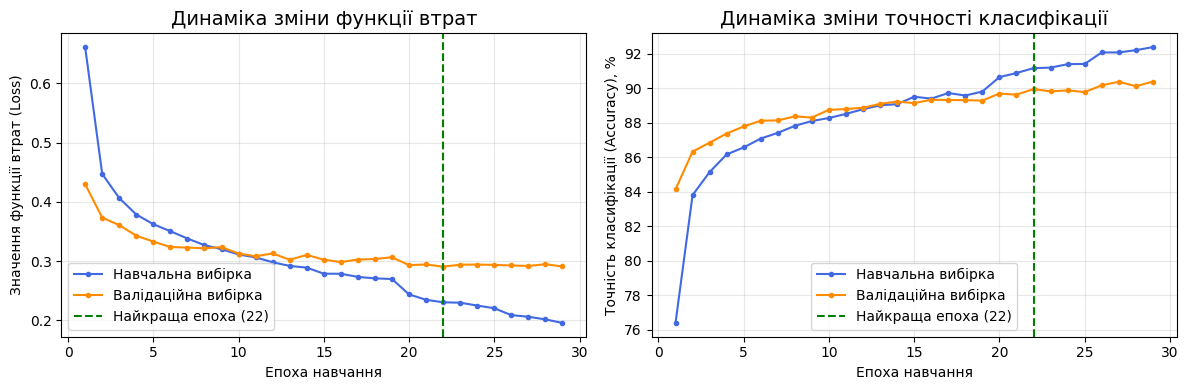

In [22]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:

train_loss = history.history["loss"]
val_loss = history.history["val_loss"]

train_accuracy = np.array(history.history["accuracy"]) * 100
val_accuracy = np.array(history.history["val_accuracy"]) * 100

epochs_range = range(1, len(train_loss) + 1)

best_epoch = np.argmin(val_loss) + 1

plt.figure(figsize = (12, 4))

plt.subplot(1, 2, 1)

plt.plot(epochs_range, train_loss,
         color = "royalblue", marker = "o", markersize = 3,
         label = "Навчальна вибірка")

plt.plot(epochs_range, val_loss,
         color = "darkorange", marker = "o", markersize = 3,
         label = "Валідаційна вибірка")

plt.axvline(x = best_epoch, color = "green", linestyle = "--",
            label = f"Найкраща епоха ({best_epoch})")

plt.title("Динаміка зміни функції втрат", fontsize = 14)
plt.xlabel("Епоха навчання")
plt.ylabel("Значення функції втрат (Loss)")
plt.legend()
plt.grid(alpha = 0.3)

plt.subplot(1, 2, 2)

plt.plot(epochs_range, train_accuracy,
         color = "royalblue", marker = "o", markersize = 3,
         label = "Навчальна вибірка")

plt.plot(epochs_range, val_accuracy,
         color = "darkorange", marker = "o", markersize = 3,
         label = "Валідаційна вибірка")

plt.axvline(x = best_epoch, color = "green", linestyle = "--",
            label = f"Найкраща епоха ({best_epoch})")

plt.title("Динаміка зміни точності класифікації", fontsize = 14)
plt.xlabel("Епоха навчання")
plt.ylabel("Точність класифікації (Accuracy), %")
plt.legend()
plt.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

###**Пояснення:**

На основі збереженої історії навчання нейронної мережі (`history`) побудовано два графіки, які відображають динаміку зміни значень функції втрат (`loss`) та точності класифікації (`accuracy`) на навчальній і валідаційній вибірках протягом 29 епох навчання.

Для побудови графіків використано бібліотеку Matplotlib. З історії навчання отримано значення таких показників:

- `loss` — значення функції втрат на навчальній вибірці;

- `val_loss` — значення функції втрат на валідаційній вибірці;

- `accuracy` — точність класифікації на навчальній вибірці;

- `val_accuracy` — точність класифікації на валідаційній вибірці.

Для більш наочного представлення результатів значення точності класифікації переведено у відсотки. На обох графіках синім кольором позначено показники навчальної вибірки, помаранчевим — показники валідаційної вибірки, а зеленою вертикальною пунктирною лінією — найкращу епоху навчання (22-гу), визначену за мінімальним значенням функції втрат на валідаційній вибірці.

**Аналіз графіка динаміки зміни функції втрат (`Loss`).**

На першому графіку спостерігається загальне зменшення значень функції втрат на навчальній та валідаційній вибірках. Найбільш інтенсивне зменшення відбувається протягом перших епох, що свідчить про ефективне засвоєння нейронною мережею основних закономірностей у вхідних даних.

Значення функції втрат на навчальній вибірці зменшилося з 0.6608 на першій епосі до 0.1959 на останній. На валідаційній вибірці значення функції втрат зменшилося з 0.4297 до мінімального значення 0.2906, отриманого на 22-й епосі.

Починаючи приблизно з 11–12-ї епохи, спостерігається поступове збільшення розбіжності між кривими навчальної та валідаційної вибірок. Після 19-ї епохи, на якій відбулося перше зменшення швидкості навчання, помітне подальше зниження значень функції втрат.

Після 22-ї епохи функція втрат на навчальній вибірці продовжує зменшуватися, тоді як на валідаційній вибірці її значення стабілізується з незначними коливаннями та вже не досягає нового мінімуму. Така поведінка свідчить про появу ознак перенавчання нейронної мережі.

**Аналіз графіка динаміки зміни точності класифікації (`Accuracy`).**

На другому графіку спостерігається поступове зростання точності класифікації на обох вибірках. Найбільш інтенсивне зростання точності відбувається протягом перших епох навчання, після чого темп покращення показників поступово зменшується.

На початкових епохах точність на валідаційній вибірці перевищує точність на навчальній вибірці. Однією з причин цього є застосування регуляризації `Dropout`, яка активна під час навчання нейронної мережі, але не використовується під час валідації.

Приблизно на 13–15-й епохах значення точності на навчальній та валідаційній вибірках зближуються, після чого навчальна точність переважно перевищує валідаційну, а розбіжність між кривими поступово збільшується. Наприкінці навчання точність на навчальній вибірці досягає 92.39%, тоді як точність на валідаційній вибірці стабілізується на рівні близько 90% та досягає максимального значення 90.39% на останній, 29-й епосі.

Для детальнішого аналізу динаміки навчання порівняно показники на першій, найкращій та останній епохах.

| Показник | 1-ша епоха | 22-га епоха (найкраща) | 29-та епоха (остання) |
|---|---:|---:|---:|
| Функція втрат на навчальній вибірці (`loss`) | 0.6608 | 0.2307 | 0.1959 |
| Функція втрат на валідаційній вибірці (`val_loss`) | 0.4297 | **0.2906** | 0.2910 |
| Точність на навчальній вибірці (`accuracy`) | 76.40% | 91.17% | 92.39% |
| Точність на валідаційній вибірці (`val_accuracy`) | 84.14% | **89.96%** | 90.39% |
| Абсолютна розбіжність між показниками точності | 7.74 в. п. | 1.21 в. п. | 2.00 в. п. |

---

Розбіжність між показниками навчальної та валідаційної точності на найкращій епосі становить 1.21 відсотка, а на останній — 2.00 відсотка. Збільшення розбіжності між показниками точності разом із відсутністю подальшого зменшення валідаційної функції втрат свідчить про поступове посилення ознак перенавчання на завершальному етапі навчання.

Застосування `callback`-функції `ReduceLROnPlateau` забезпечило триразове зменшення швидкості навчання, а використання `EarlyStopping` дозволило своєчасно припинити навчання на 29-й епосі та відновити вагові коефіцієнти, отримані на 22-й епосі, для якої зафіксовано мінімальне значення функції втрат на валідаційній вибірці.

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [23]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:

test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose = 0
)

print("Результати оцінювання моделі на тестовій вибірці:")
print(f"Значення функції втрат (Loss): {test_loss:.4f}")
print(f"Точність класифікації (Accuracy): {test_accuracy:.4f}")
print(f"Точність класифікації у відсотках: {test_accuracy * 100:.2f}%")

y_pred_prob = model.predict(x_test, verbose = 0)

y_pred = np.argmax(y_pred_prob, axis = 1)

correct_predictions = np.sum(y_pred == y_test)
incorrect_predictions = np.sum(y_pred != y_test)

print("\nРезультати класифікації зображень:")
print(f"Загальна кількість тестових зображень: {len(y_test)}")
print(f"Кількість правильно класифікованих зображень: {correct_predictions}")
print(f"Кількість неправильно класифікованих зображень: {incorrect_predictions}")

print("\nКласифікаційний звіт:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names = class_names,
    digits = 4
))

target_accuracy = 0.87

print("Перевірка досягнення цільової точності:")
print(f"Цільова точність: {target_accuracy * 100:.2f}%")
print(f"Отримана точність: {test_accuracy * 100:.2f}%")
print(f"Відхилення від цільової точності: {(test_accuracy - target_accuracy) * 100:+.2f} в. п.")

if test_accuracy >= target_accuracy:
    print("Вимогу щодо точності класифікації виконано!")
else:
    print("Вимогу щодо точності класифікації не виконано!")

Результати оцінювання моделі на тестовій вибірці:
Значення функції втрат (Loss): 0.3255
Точність класифікації (Accuracy): 0.8908
Точність класифікації у відсотках: 89.08%

Результати класифікації зображень:
Загальна кількість тестових зображень: 10000
Кількість правильно класифікованих зображень: 8908
Кількість неправильно класифікованих зображень: 1092

Класифікаційний звіт:

                precision    recall  f1-score   support

Футболка / топ     0.8256    0.8570    0.8410      1000
         Штани     0.9819    0.9760    0.9789      1000
       Пуловер     0.7838    0.8300    0.8062      1000
         Сукня     0.8888    0.9030    0.8958      1000
        Пальто     0.8114    0.7960    0.8036      1000
       Сандалі     0.9847    0.9640    0.9742      1000
       Сорочка     0.7418    0.6810    0.7101      1000
      Кросівки     0.9417    0.9690    0.9552      1000
         Сумка     0.9818    0.9710    0.9764      1000
    Ботильйони     0.9639    0.9610    0.9624      1000

  

###**Пояснення:**

За допомогою методу `model.evaluate()` визначено значення функції втрат (`loss`) та точності класифікації (`accuracy`) на тестовій вибірці. Для більш наочного представлення результатів отримане значення точності переведено у відсотки.

За допомогою методу `model.predict()` отримано прогнозовані ймовірності належності кожного тестового зображення до 10 класів. Функцією `np.argmax()` визначено індекс класу з найбільшою прогнозованою ймовірністю для кожного зображення. Шляхом порівняння прогнозованих міток класів (`y_pred`) із фактичними (`y_test`) визначено кількість правильно та неправильно класифікованих зображень.

Для детальнішого оцінювання якості класифікації за допомогою функції `classification_report()` сформовано класифікаційний звіт для всіх 10 класів набору даних `Fashion MNIST`, який містить такі показники:

- `Precision` — частка правильних прогнозів певного класу серед усіх прогнозів цього класу;

- `Recall` — частка правильно розпізнаних зображень певного класу серед усіх зображень, які фактично належать до цього класу;

- `F1-score` — гармонійне середнє значень `Precision` та `Recall`;

- `Support` — кількість зображень відповідного класу в тестовій вибірці.

Найкращі результати класифікації за метрикою `F1-score` отримано для класів «Штани» (0.9789), «Сумка» (0.9764), «Сандалі» (0.9742), «Ботильйони» (0.9624) та «Кросівки» (0.9552). Високі значення метрик `Precision`, `Recall` та `F1-score` свідчать про здатність нейронної мережі ефективно розпізнавати зображення цих класів. Однією з можливих причин є наявність характерних візуальних ознак, які дозволяють відрізняти відповідні предмети від інших категорій.

Для класу «Сукня» також отримано достатньо високе значення `F1-score` — 0.8958. Дещо нижчі результати отримано для класів «Футболка / топ» (0.8410), «Пуловер» (0.8062) та «Пальто» (0.8036). Це може бути пов’язано зі схожістю форми, контурів та інших візуальних характеристик відповідних предметів одягу.

Найнижче значення `F1-score` отримано для класу «Сорочка» — 0.7101. Значення `Recall` для цього класу становить 0.6810, тобто нейронна мережа правильно розпізнала лише 681 із 1000 зображень сорочок, а 319 зображень було віднесено до інших класів. Можливою причиною є візуальна схожість сорочок із футболками, пуловерами та іншими предметами верхнього одягу, особливо за низької роздільної здатності зображень (28 × 28 пікселів). Для підтвердження конкретних помилок між класами необхідно проаналізувати матрицю помилок класифікації.

Середні значення метрик `Precision`, `Recall` та `F1-score` становлять 0.8905, 0.8908 та 0.8904 відповідно. Значення `macro avg` та `weighted avg` збігаються, оскільки тестова вибірка є збалансованою та містить однакову кількість зображень кожного класу — по 1000.

Розбіжність між точністю класифікації на валідаційній та тестовій вибірках становить лише 0.88 відсотка. Незважаючи на виявлені на попередньому етапі ознаки перенавчання, отримані результати свідчать про достатньо хорошу узагальнювальну здатність нейронної мережі та її здатність класифікувати зображення, які не використовувалися під час навчання.

### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

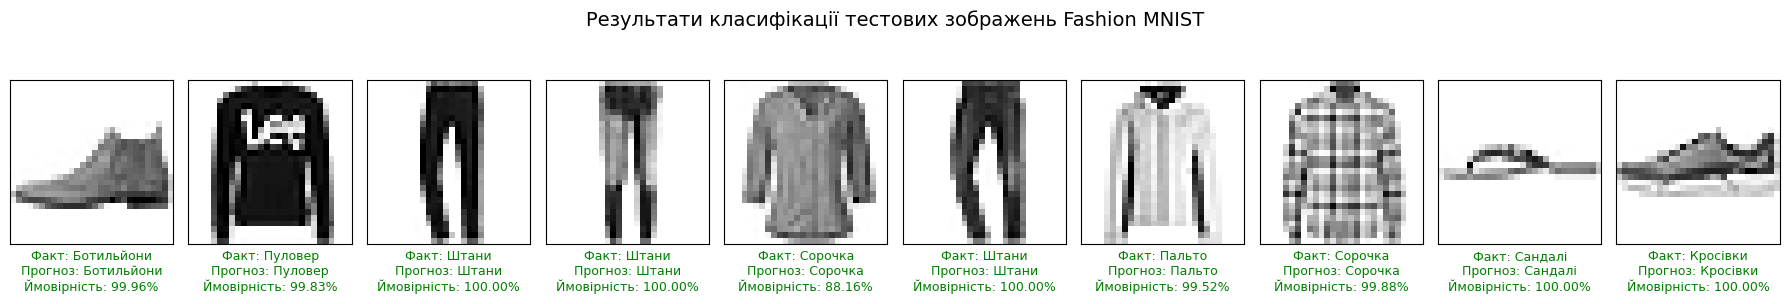

Результати класифікації перших 10 тестових зображень:
Кількість правильних прогнозів: 10
Кількість неправильних прогнозів: 0
Точність класифікації цих зображень: 100.00%


In [24]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:

plt.figure(figsize = (18, 3))

for i in range(10):
    plt.subplot(1, 10, i + 1)

    plt.imshow(x_test[i], cmap = "gray_r")

    true_class = y_test[i]
    predicted_class = y_pred[i]
    confidence = y_pred_prob[i][predicted_class] * 100

    if true_class == predicted_class:
        color = "green"
    else:
        color = "red"

    plt.xlabel(
        f"Факт: {class_names[true_class]}\n"
        f"Прогноз: {class_names[predicted_class]}\n"
        f"Ймовірність: {confidence:.2f}%",
        color = color,
        fontsize = 9
    )

    plt.xticks([])
    plt.yticks([])

plt.suptitle("Результати класифікації тестових зображень Fashion MNIST",
             fontsize = 14, y = 0.95)

plt.tight_layout()
plt.show()

correct_10 = np.sum(y_pred[:10] == y_test[:10])
incorrect_10 = 10 - correct_10

print("Результати класифікації перших 10 тестових зображень:")
print(f"Кількість правильних прогнозів: {correct_10}")
print(f"Кількість неправильних прогнозів: {incorrect_10}")
print(f"Точність класифікації цих зображень: {correct_10 / 10 * 100:.2f}%")

###**Пояснення:**

Виконано візуалізацію результатів класифікації перших 10 зображень незалежної тестової вибірки набору даних `Fashion MNIST`. Для побудови візуалізації використано бібліотеку Matplotlib та отримані на попередньому етапі прогнозовані мітки класів (`y_pred`) і прогнозовані ймовірності належності зображень до відповідних класів (`y_pred_prob`).

За допомогою функції `plt.subplot()` сформовано область відображення, яка складається з одного рядка та десяти стовпців. Зображення представлено у відтінках сірого на білому тлі за допомогою параметра `cmap = "gray_r"`.

Для кожного тестового зображення визначено фактичний клас (`true_class`), прогнозований нейронною мережею клас (`predicted_class`) та прогнозовану ймовірність належності зображення до обраного моделлю класу (`confidence`), виражену у відсотках.

Для наочного представлення правильності класифікації використано кольорове позначення підписів:

- зелений колір — прогнозований клас збігається з фактичним, тобто зображення класифіковано правильно;

- червоний колір — прогнозований клас не збігається з фактичним, тобто допущено помилку класифікації.

За результатами візуального аналізу встановлено, що нейронна мережа правильно класифікувала всі 10 представлених тестових зображень, про що свідчить зелений колір підписів під кожним із них. Значення прогнозованих ймовірностей перебувають у діапазоні від 88.16% до 100.00% (з урахуванням округлення).

Найнижчу прогнозовану ймовірність отримано для п’ятого зображення, яке належить до класу «Сорочка», — 88.16%. Це узгоджується з результатами класифікаційного звіту, отриманого на попередньому етапі, відповідно до якого саме клас «Сорочка» характеризується найнижчим значенням `F1-score` (0.7101). Водночас обидва представлені зображення цього класу було класифіковано правильно.

Отримана точність 100% стосується лише перших 10 зображень тестової вибірки та не характеризує якість класифікації всієї тестової вибірки. Загальна точність нейронної мережі, визначена на 10 000 тестових зображеннях на попередньому етапі, становить 89.08%.

**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  
_..._

###**Висновок до завдання 1:**

За результатами оцінювання навченої нейронної мережі на незалежній тестовій вибірці набору даних `Fashion MNIST` отримано точність класифікації (`Accuracy`) 0.8908 (89.08%), значення функції втрат (`Loss`) — 0.3255 та середнє значення `F1-score` — 0.8904. Нейронна мережа правильно класифікувала 8 908 із 10 000 тестових зображень, а для 1 092 зображень допущено помилки класифікації.

За результатами аналізу класифікаційного звіту встановлено, що найбільшу кількість помилок розпізнавання допущено для класів «Сорочка» (319 помилок, `F1-score` = 0.7101), «Пальто» (204 помилки, `F1-score` = 0.8036), «Пуловер» (170 помилок, `F1-score` = 0.8062) та «Футболка / топ» (143 помилки, `F1-score` = 0.8410). Можливою причиною цього є візуальна схожість відповідних предметів одягу за формою, контурами та іншими характеристиками, особливо за низької роздільної здатності зображень (28 × 28 пікселів). Найкращі результати за метрикою `F1-score` отримано для класів «Штани» (0.9789), «Сумка» (0.9764) та «Сандалі» (0.9742).

Отримана точність класифікації на тестовій вибірці становить 89.08%, що перевищує встановлене умовою завдання мінімальне порогове значення 87% на 2.08 відсотка. Отже, вимогу щодо мінімальної точності класифікації виконано.


# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [25]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:

!pip install -q keras-tuner

import keras_tuner as kt

from keras_tuner import RandomSearch
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2

print("Бібліотеку Keras Tuner успішно встановлено та підключено!")
print(f"Версія Keras Tuner: {kt.__version__}")
print("Алгоритм пошуку гіперпараметрів: RandomSearch")
print("Метод регуляризації: L2")
print(f"Наявність GPU: {'Так' if tf.config.list_physical_devices('GPU') else 'Ні'}")

Бібліотеку Keras Tuner успішно встановлено та підключено!
Версія Keras Tuner: 1.4.8
Алгоритм пошуку гіперпараметрів: RandomSearch
Метод регуляризації: L2
Наявність GPU: Ні


###**Пояснення:**

За допомогою команди `!pip install -q keras-tuner` здійснено встановлення необхідної бібліотеки в середовищі Google Colab. Параметр `-q` забезпечує скорочене виведення службових повідомлень під час встановлення.

Підключено необхідні бібліотеки та компоненти для подальшої побудови, навчання й оптимізації конфігурації нейронної мережі:

- `keras_tuner` — бібліотека для автоматизованого пошуку гіперпараметрів нейронних мереж;

- `RandomSearch` — алгоритм випадкового пошуку, який здійснює вибір та перевірку різних комбінацій гіперпараметрів із заданого простору пошуку;

- `Sequential` — створення послідовної архітектури нейронної мережі;

- `Dense` — створення повнозв’язних шарів нейронної мережі;

- `Flatten` — перетворення двовимірних зображень на одновимірні вектори;

- `Dropout` — зменшення ризику перенавчання шляхом випадкового відключення частини вихідних елементів шару під час навчання;

- `BatchNormalization` — нормалізація проміжних активацій нейронної мережі, яка може сприяти стабілізації та прискоренню процесу навчання;

- `l2` — регуляризація `L2`, яка передбачає додавання до функції втрат штрафу, пропорційного сумі квадратів вагових коефіцієнтів, для зменшення ризику перенавчання моделі.

Алгоритм `RandomSearch` дозволяє автоматизувати процес підбору гіперпараметрів шляхом випадкового формування комбінацій їхніх значень, побудови та навчання відповідних моделей із подальшим оцінюванням їхньої якості на валідаційній вибірці.

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [26]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:

x_train_tuner = x_train_new
y_train_tuner = y_train_new

x_val_tuner = x_val
y_val_tuner = y_val

x_test_tuner = x_test
y_test_tuner = y_test

print("Розміри масивів навчальної вибірки:")
print(f"x_train_tuner: {x_train_tuner.shape}")
print(f"y_train_tuner: {y_train_tuner.shape}")

print("\nРозміри масивів валідаційної вибірки:")
print(f"x_val_tuner: {x_val_tuner.shape}")
print(f"y_val_tuner: {y_val_tuner.shape}")

print("\nРозміри масивів тестової вибірки:")
print(f"x_test_tuner: {x_test_tuner.shape}")
print(f"y_test_tuner: {y_test_tuner.shape}")

print("\nПеревірка нормалізації даних:")

print(f"Навчальна вибірка: [{x_train_tuner.min()}; {x_train_tuner.max()}]")
print(f"Тип даних: {x_train_tuner.dtype}")

print(f"Валідаційна вибірка: [{x_val_tuner.min()}; {x_val_tuner.max()}]")
print(f"Тип даних: {x_val_tuner.dtype}")

print(f"Тестова вибірка: [{x_test_tuner.min()}; {x_test_tuner.max()}]")
print(f"Тип даних: {x_test_tuner.dtype}")

print("\nРозподіл зображень за класами:")

for i in range(len(class_names)):
    train_count = np.sum(y_train_tuner == i)
    val_count = np.sum(y_val_tuner == i)
    test_count = np.sum(y_test_tuner == i)

    print(f"{class_names[i]:15s} | "
          f"Train: {train_count} | "
          f"Validation: {val_count} | "
          f"Test: {test_count}")

print("\nДані підготовлено до автоматизованого добору гіперпараметрів!")
print("Для пошуку гіперпараметрів використовуються лише навчальна та валідаційна вибірки.")
print("Тестова вибірка зарезервована для фінального оцінювання моделі.")

Розміри масивів навчальної вибірки:
x_train_tuner: (48000, 28, 28)
y_train_tuner: (48000,)

Розміри масивів валідаційної вибірки:
x_val_tuner: (12000, 28, 28)
y_val_tuner: (12000,)

Розміри масивів тестової вибірки:
x_test_tuner: (10000, 28, 28)
y_test_tuner: (10000,)

Перевірка нормалізації даних:
Навчальна вибірка: [0.0; 1.0]
Тип даних: float32
Валідаційна вибірка: [0.0; 1.0]
Тип даних: float32
Тестова вибірка: [0.0; 1.0]
Тип даних: float32

Розподіл зображень за класами:
Футболка / топ  | Train: 4800 | Validation: 1200 | Test: 1000
Штани           | Train: 4800 | Validation: 1200 | Test: 1000
Пуловер         | Train: 4800 | Validation: 1200 | Test: 1000
Сукня           | Train: 4800 | Validation: 1200 | Test: 1000
Пальто          | Train: 4800 | Validation: 1200 | Test: 1000
Сандалі         | Train: 4800 | Validation: 1200 | Test: 1000
Сорочка         | Train: 4800 | Validation: 1200 | Test: 1000
Кросівки        | Train: 4800 | Validation: 1200 | Test: 1000
Сумка           | Train: 

###**Пояснення:**

Повторно використано нормалізовані дані та сформовані у першому завданні навчальну, валідаційну й тестову вибірки без повторного завантаження, нормалізації та розподілу зображень.

Для логічного відокремлення даних другого завдання від даних першого завдання створено окремі змінні із суфіксом `_tuner`, які посилаються на раніше сформовані масиви:

- `x_train_tuner`, `y_train_tuner` — зображення та мітки класів навчальної вибірки, призначеної для навчання моделей із різними комбінаціями гіперпараметрів;

- `x_val_tuner`, `y_val_tuner` — зображення та мітки класів валідаційної вибірки, призначеної для оцінювання моделей під час пошуку гіперпараметрів та вибору найкращої конфігурації;

- `x_test_tuner`, `y_test_tuner` — зображення та мітки класів тестової вибірки, призначеної виключно для фінального оцінювання якості оптимізованої моделі.

За допомогою атрибута `shape` визначено розмірності масивів, методів `min()` та `max()` — діапазони значень пікселів, а атрибута `dtype` — тип даних зображень.

Отримані результати підтверджують, що значення пікселів зображень усіх трьох вибірок нормалізовано до діапазону [0; 1], а тип даних `float32` є придатним для навчання нейронних мереж засобами `TensorFlow` та `Keras`.

Додатково за допомогою функції `np.sum()` визначено кількість зображень кожного класу в навчальній, валідаційній та тестовій вибірках.

За результатами аналізу розподілу зображень встановлено, що всі три вибірки є повністю збалансованими: кожен із 10 класів становить 10% від загальної кількості зображень відповідної вибірки. Це підтверджує коректність виконаного у першому завданні стратифікованого розподілу навчальних даних та відсутність дисбалансу класів. Таким чином, застосовувати додаткові методи балансування класів не потрібно.

### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [27]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:

def build_model(hp):

    tuner_model = Sequential()

    tuner_model.add(layers.Input(shape = (28, 28)))
    tuner_model.add(Flatten())

    num_layers = hp.Int(
        "num_layers",
        min_value = 1,
        max_value = 3,
        step = 1
    )

    for i in range(3):

        with hp.conditional_scope(
            "num_layers",
            list(range(i + 1, 4))
        ):
            units = hp.Int(
                f"units_{i + 1}",
                min_value = 32,
                max_value = 512,
                step = 32
            )

        if i < num_layers:

            tuner_model.add(Dense(
                units = units,
                activation = "relu",
                kernel_regularizer = l2(0.0001)
            ))

            tuner_model.add(Dropout(0.3))

    tuner_model.add(Dense(10, activation = "softmax"))

    learning_rate = hp.Choice(
        "learning_rate",
        values = [0.01, 0.001, 0.0001]
    )

    tuner_model.compile(
        optimizer = keras.optimizers.Adam(
            learning_rate = learning_rate
        ),
        loss = "sparse_categorical_crossentropy",
        metrics = ["accuracy"]
    )

    return tuner_model

hp_demo = kt.HyperParameters()
demo_model = build_model(hp_demo)

print("Функцію побудови моделі успішно створено!")

print("\nПростір пошуку гіперпараметрів:")
print("Кількість прихованих шарів: від 1 до 3")
print("Кількість нейронів у кожному шарі: від 32 до 512")
print("Крок зміни кількості нейронів: 32")
print("Швидкість навчання: 0.01, 0.001, 0.0001")

print("\nФіксовані параметри моделі:")
print("Функція активації прихованих шарів: ReLU")
print("Коефіцієнт Dropout: 0.3")
print("Коефіцієнт регуляризації L2: 0.0001")
print("Функція активації вихідного шару: softmax")
print("Кількість нейронів вихідного шару: 10")
print("Оптимізатор: Adam")
print("Функція втрат: sparse_categorical_crossentropy")
print("Метрика оцінювання: accuracy")

print("\nГіперпараметри демонстраційної моделі:")
for name, value in hp_demo.values.items():
    print(f"{name}: {value}")

print("\nАрхітектура демонстраційної моделі:")
demo_model.summary()

Функцію побудови моделі успішно створено!

Простір пошуку гіперпараметрів:
Кількість прихованих шарів: від 1 до 3
Кількість нейронів у кожному шарі: від 32 до 512
Крок зміни кількості нейронів: 32
Швидкість навчання: 0.01, 0.001, 0.0001

Фіксовані параметри моделі:
Функція активації прихованих шарів: ReLU
Коефіцієнт Dropout: 0.3
Коефіцієнт регуляризації L2: 0.0001
Функція активації вихідного шару: softmax
Кількість нейронів вихідного шару: 10
Оптимізатор: Adam
Функція втрат: sparse_categorical_crossentropy
Метрика оцінювання: accuracy

Гіперпараметри демонстраційної моделі:
num_layers: 1
units_1: 32
learning_rate: 0.01

Архітектура демонстраційної моделі:


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_3 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 32)             │        25,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,450 (99.41 KB)

 Trainable params: 25,450 (99.41 KB)

 Non-trainable params: 0 (0.00 B)

###**Пояснення:**

Реалізовано функцію `build_model(hp)`, яка приймає об’єкт гіперпараметрів `hp` бібліотеки `Keras Tuner`, формує архітектуру послідовної нейронної мережі відповідно до заданої комбінації гіперпараметрів та повертає скомпільовану модель. Створена функція надалі використовуватиметься алгоритмом `RandomSearch` для автоматизованої побудови й навчання нейронних мереж із різними конфігураціями.

За допомогою шару `Input` визначено вхідну розмірність зображень (28, 28), а за допомогою шару `Flatten` виконуватиметься перетворення двовимірних зображень на одновимірні вектори із 784 значень.

Для визначення простору пошуку гіперпараметрів використано такі методи бібліотеки `Keras Tuner`:

- `hp.Int()` — визначення діапазону допустимих цілочисельних значень гіперпараметра із заданим кроком;

- `hp.Choice()` — визначення переліку конкретних допустимих значень гіперпараметра;

- `hp.conditional_scope()` — встановлення умовної залежності між гіперпараметрами, що дозволяє підбирати кількість нейронів лише для тих прихованих шарів, які передбачені поточною конфігурацією нейронної мережі.

Кількість нейронів у кожному прихованому повнозв’язному шарі може набувати одного із 16 допустимих значень: 32, 64, 96, 128, 160, 192, 224, 256, 288, 320, 352, 384, 416, 448, 480 та 512.

Використання методу `hp.conditional_scope()` дозволяє уникнути підбору гіперпараметрів для відсутніх шарів. Наприклад, якщо обрана конфігурація містить лише один прихований шар, активним буде гіперпараметр `units_1`, а гіперпараметри `units_2` та `units_3` не використовуватимуться.

Для кожного прихованого повнозв’язного шару застосовано функцію активації `ReLU`, регуляризацію `L2` із коефіцієнтом 0.0001 та шар `Dropout` із коефіцієнтом 0.3.

Регуляризація `Dropout` передбачає випадкове відключення в середньому 30% вихідних елементів відповідного шару під час навчання, що зменшує залежність моделі від окремих нейронів. Регуляризація `L2` передбачає додавання до функції втрат штрафу, пропорційного сумі квадратів вагових коефіцієнтів:

**Ltotal = Lclassification + λ∑wi^2**,

де **Ltotal** - загальне значення функції втрат, **Lclassification** - значення функції втрат класифікації, **λ** - коефіцієнт регуляризації `L2` (0.0001), **wi** - вагові коефіцієнти, до яких застосовано регуляризацію.

Поєднання `Dropout` та `L2` спрямоване на зменшення ризику перенавчання й покращення узагальнювальної здатності нейронної мережі.

Для перевірки коректності реалізованої функції `build_model()` створено об’єкт `kt.HyperParameters()` та побудовано демонстраційну нейронну мережу `demo_model` із початковими значеннями гіперпараметрів.

За допомогою методу `demo_model.summary()` виведено архітектуру демонстраційної нейронної мережі, вихідні розмірності її шарів та кількість параметрів.

Демонстраційна нейронна мережа містить 4 шари (без урахування вхідного шару) та 25 450 навчуваних параметрів. Відсутність ненавчуваних параметрів пояснюється тим, що всі вагові коефіцієнти та параметри зміщення повнозв’язних шарів підлягають оновленню під час навчання, а шари `Flatten` та `Dropout` не містять власних вагових параметрів.

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [28]:
# Ініціалізуйте RandomSearch.
# Ваш код:

tuner_dir = os.path.join(save_dir, "Keras_Tuner")

os.makedirs(tuner_dir, exist_ok = True)

tuner = RandomSearch(
    hypermodel = build_model,
    objective = kt.Objective("val_accuracy", direction = "max"),
    max_trials = 3,
    executions_per_trial = 1,
    seed = 42,
    directory = tuner_dir,
    project_name = "fashion_mnist_random_search",
    overwrite = True
)

print("Алгоритм RandomSearch успішно ініціалізовано!")

print("\nПараметри пошуку гіперпараметрів:")
print("Алгоритм пошуку: RandomSearch")
print("Критерій оцінювання: val_accuracy")
print("Напрям оптимізації: максимізація")
print("Максимальна кількість спроб: 3")
print("Кількість виконань на одну спробу: 1")
print("Фіксоване значення random seed: 42")

print(f"\nКаталог збереження результатів: {tuner_dir}")
print(f"Назва проєкту: {tuner.project_name}")
print(f"Повний шлях до результатів: {tuner.project_dir}")

print("\nПростір пошуку гіперпараметрів:")
tuner.search_space_summary()

Алгоритм RandomSearch успішно ініціалізовано!

Параметри пошуку гіперпараметрів:
Алгоритм пошуку: RandomSearch
Критерій оцінювання: val_accuracy
Напрям оптимізації: максимізація
Максимальна кількість спроб: 3
Кількість виконань на одну спробу: 1
Фіксоване значення random seed: 42

Каталог збереження результатів: /content/drive/MyDrive/ML_Lab10/Keras_Tuner
Назва проєкту: fashion_mnist_random_search
Повний шлях до результатів: /content/drive/MyDrive/ML_Lab10/Keras_Tuner/fashion_mnist_random_search

Простір пошуку гіперпараметрів:
Search space summary
Default search space size: 5
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units_1 (Int)
{'default': None, 'conditions': [{'class_name': 'Parent', 'config': {'name': 'num_layers', 'values': [1, 2, 3]}}], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
units_2 (Int)
{'default': None, 'conditions': [{'class_name': 'Parent', 'config': {'name': 'num_laye

###**Пояснення:**

Для побудови та компіляції моделей із різними конфігураціями використано реалізовану на попередньому етапі функцію `build_model(hp)`.

Як критерій вибору найкращої конфігурації нейронної мережі встановлено точність класифікації на валідаційній вибірці (`val_accuracy`). За допомогою параметра `direction = "max"` визначено напрям оптимізації — максимізацію значення валідаційної точності.

Максимальну кількість спроб пошуку встановлено рівною трьом (`max_trials = 3`), а кількість виконань для кожної комбінації гіперпараметрів — одному (`executions_per_trial = 1`).

Для збереження результатів автоматизованого пошуку за допомогою методів `os.path.join()` та `os.makedirs()` сформовано окремий каталог `Keras_Tuner` на Google Drive у раніше створеному каталозі ML_Lab10.

За допомогою методу `tuner.search_space_summary()` виведено інформацію про зареєстрований простір пошуку гіперпараметрів. За результатами виконання коду встановлено, що простір пошуку містить п’ять гіперпараметрів (`Default search space size: 5`).

Отримані результати підтверджують коректність реєстрації всіх гіперпараметрів та їхніх умовних залежностей. Зокрема, кількість нейронів другого і третього прихованих шарів підбиратиметься лише за наявності відповідних шарів у поточній конфігурації нейронної мережі.

Оскільки кількість нейронів кожного прихованого шару може набувати одного із 16 допустимих значень, а швидкість навчання — одного із трьох, загальну кількість можливих комбінацій гіперпараметрів можна визначити за формулою:

N = 3 * (16^1 + 16^2 + 16^3)

N = 3 * (16 + 256 + 4096) = 13104

Таким чином, визначений простір пошуку містить 13 104 можливі конфігурації нейронної мережі. Оскільки встановлено обмеження `max_trials = 3`, алгоритм `RandomSearch` досліджуватиме лише три випадково обрані комбінації гіперпараметрів. Тому отримана в подальшому конфігурація вважатиметься найкращою серед перевірених, а не гарантовано оптимальною серед усіх можливих конфігурацій.

### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [29]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:

early_stopping_search = EarlyStopping(
    monitor = "val_accuracy",
    mode = "max",
    patience = 7,
    restore_best_weights = True,
    verbose = 1
)

reduce_lr_search = ReduceLROnPlateau(
    monitor = "val_accuracy",
    mode = "max",
    factor = 0.5,
    patience = 3,
    min_lr = 0.000001,
    verbose = 1
)

print("Початок автоматизованого пошуку гіперпараметрів:\n")

tuner.search(
    x_train_tuner,
    y_train_tuner,
    validation_data = (x_val_tuner, y_val_tuner),
    epochs = 30,
    batch_size = 128,
    callbacks = [early_stopping_search, reduce_lr_search],
    verbose = 1
)

print("\nАвтоматизований пошук гіперпараметрів завершено!")

print("\nРезультати всіх спроб пошуку:")
tuner.results_summary(num_trials = 3)

best_hp = tuner.get_best_hyperparameters(num_trials = 1)[0]

print("\nНайкраща комбінація гіперпараметрів:")

print(f"Кількість прихованих шарів: {best_hp.get('num_layers')}")

for i in range(best_hp.get("num_layers")):
    print(f"Кількість нейронів у шарі {i + 1}: "
          f"{best_hp.get(f'units_{i + 1}')}")

print(f"Швидкість навчання: {best_hp.get('learning_rate')}")
print("Коефіцієнт Dropout: 0.3")
print("Коефіцієнт регуляризації L2: 0.0001")

best_trial = tuner.oracle.get_best_trials(num_trials = 1)[0]

print(f"\nІдентифікатор найкращої спроби: {best_trial.trial_id}")
print(f"Найкраща валідаційна точність під час пошуку: "
      f"{best_trial.score * 100:.2f}%")

keras.utils.set_random_seed(42)

best_model = build_model(best_hp)

print("\nАрхітектура моделі з найкращими гіперпараметрами:")
best_model.summary()

early_stopping_best = EarlyStopping(
    monitor = "val_accuracy",
    mode = "max",
    patience = 7,
    restore_best_weights = True,
    verbose = 1
)

reduce_lr_best = ReduceLROnPlateau(
    monitor = "val_accuracy",
    mode = "max",
    factor = 0.5,
    patience = 3,
    min_lr = 0.000001,
    verbose = 1
)

print("\nПочаток навчання моделі з найкращими гіперпараметрами:\n")

history_tuner = best_model.fit(
    x_train_tuner,
    y_train_tuner,
    validation_data = (x_val_tuner, y_val_tuner),
    epochs = 50,
    batch_size = 128,
    callbacks = [early_stopping_best, reduce_lr_best],
    verbose = 1
)

best_epoch_tuner = np.argmax(
    history_tuner.history["val_accuracy"]
)

print("\nНавчання моделі з найкращими гіперпараметрами завершено!")

print(f"Кількість виконаних епох: "
      f"{len(history_tuner.history['loss'])}")

print(f"Найкраща епоха за val_accuracy: "
      f"{best_epoch_tuner + 1}")

print(f"Точність на навчальній вибірці на найкращій епосі: "
      f"{history_tuner.history['accuracy'][best_epoch_tuner] * 100:.2f}%")

print(f"Точність на валідаційній вибірці на найкращій епосі: "
      f"{history_tuner.history['val_accuracy'][best_epoch_tuner] * 100:.2f}%")

print(f"Значення val_loss на найкращій епосі: "
      f"{history_tuner.history['val_loss'][best_epoch_tuner]:.4f}")

print(f"Мінімальне значення val_loss: "
      f"{min(history_tuner.history['val_loss']):.4f}")

Trial 3 Complete [00h 03m 40s]
val_accuracy: 0.9046666622161865

Best val_accuracy So Far: 0.9046666622161865
Total elapsed time: 00h 07m 44s

Автоматизований пошук гіперпараметрів завершено!

Результати всіх спроб пошуку:
Results summary
Results in /content/drive/MyDrive/ML_Lab10/Keras_Tuner/fashion_mnist_random_search
Showing 3 best trials
Objective(name="val_accuracy", direction="max")

Trial 2 summary
Hyperparameters:
num_layers: 1
units_1: 512
learning_rate: 0.001
Score: 0.9046666622161865

Trial 1 summary
Hyperparameters:
num_layers: 3
units_1: 192
units_2: 288
units_3: 64
learning_rate: 0.001
Score: 0.8985000252723694

Trial 0 summary
Hyperparameters:
num_layers: 2
units_1: 32
units_2: 224
learning_rate: 0.01
Score: 0.828083336353302

Найкраща комбінація гіперпараметрів:
Кількість прихованих шарів: 1
Кількість нейронів у шарі 1: 512
Швидкість навчання: 0.001
Коефіцієнт Dropout: 0.3
Коефіцієнт регуляризації L2: 0.0001

Ідентифікатор найкращої спроби: 2
Найкраща валідаційна точніс

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)


Початок навчання моделі з найкращими гіперпараметрами:

Epoch 1/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.7993 - loss: 0.6279 - val_accuracy: 0.8436 - val_loss: 0.4896 - learning_rate: 0.0010
Epoch 2/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.8490 - loss: 0.4748 - val_accuracy: 0.8615 - val_loss: 0.4392 - learning_rate: 0.0010
Epoch 3/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8606 - loss: 0.4369 - val_accuracy: 0.8726 - val_loss: 0.4124 - learning_rate: 0.0010
Epoch 4/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8680 - loss: 0.4154 - val_accuracy: 0.8734 - val_loss: 0.4063 - learning_rate: 0.0010
Epoch 5/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8731 - loss: 0.4013 - val_accuracy: 0.8781 - val_loss: 0.3910 - learning_rate: 0.0010
Epoch 6/50
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.8751 - loss: 0.3922 - val_accuracy: 0.8810 - val_loss: 0.3898 - learning_rate: 0.0010
Epoch 7/50
375/375 ━━━━━━

###**Пояснення:**

Для автоматичного керування процесом навчання моделей під час пошуку гіперпараметрів та повторного навчання найкращої конфігурації налаштовано `callback`-функції `EarlyStopping` та `ReduceLROnPlateau`. Як контрольований показник для обох функцій обрано точність класифікації на валідаційній вибірці (`val_accuracy`), а напрям оптимізації встановлено на максимізацію (`mode = "max"`), що відповідає критерію пошуку алгоритму `RandomSearch`.

За допомогою методу `tuner.search()` здійснено автоматизований пошук гіперпараметрів із використанням навчальної вибірки, яка містить 48 000 зображень, та валідаційної вибірки, яка містить 12 000 зображень. Максимальну кількість епох навчання для кожної досліджуваної конфігурації встановлено рівною 30 (`epochs = 30`), а розмір пакета даних — 128 зображень (`batch_size = 128`).

За допомогою методу `tuner.results_summary()` виведено результати всіх трьох спроб пошуку гіперпараметрів.

За результатами автоматизованого пошуку встановлено, що найнижчу валідаційну точність (82.81%) отримано для першої конфігурації, яка містить два приховані шари з 32 та 224 нейронами відповідно та початкову швидкість навчання 0.01. Однією з можливих причин нижчої якості класифікації є завелике початкове значення швидкості навчання, яке може ускладнювати стабільну збіжність алгоритму оптимізації. Також невелика кількість нейронів першого прихованого шару могла обмежити здатність моделі до формування інформативних ознак.

Для другої конфігурації, яка містить три приховані шари зі 192, 288 та 64 нейронами відповідно та початкову швидкість навчання 0.001, отримано валідаційну точність 89.85%.

Найкращий результат отримано для третьої конфігурації, яка містить лише один прихований повнозв’язний шар із 512 нейронами та початкову швидкість навчання 0.001. Валідаційна точність цієї конфігурації становить 90.47%, що перевищує показники першої та другої конфігурацій на 7.66 та 0.62 відсотка відповідно.

Отримані результати демонструють, що збільшення кількості прихованих шарів не обов’язково забезпечує покращення якості класифікації. Важливим є поєднання кількості шарів, кількості нейронів у них, швидкості навчання та параметрів регуляризації. Водночас за результатами трьох спроб неможливо однозначно визначити вплив кожного гіперпараметра окремо, оскільки одночасно змінювалося декілька параметрів.

За допомогою методу `tuner.get_best_hyperparameters()` отримано найкращу комбінацію гіперпараметрів, а за допомогою методу `tuner.oracle.get_best_trials()` — інформацію про найкращу спробу пошуку та відповідне значення валідаційної точності.

На основі знайдених гіперпараметрів за допомогою функції `build_model(best_hp)` створено нову нейронну мережу `best_model`. Перед її побудовою повторно встановлено фіксоване початкове значення генераторів випадкових чисел (`random seed = 42`) для підвищення відтворюваності результатів.

За допомогою методу `best_model.summary()` виведено структуру нейронної мережі, вихідні розмірності її шарів та кількість параметрів.

Створена нейронна мережа містить 4 шари (без урахування вхідного шару) та 407 050 навчуваних параметрів.

Незважаючи на те, що знайдена конфігурація містить лише один прихований повнозв’язний шар, загальна кількість навчуваних параметрів перевищує відповідний показник базової моделі першого завдання, яка містить три приховані повнозв’язні шари.

Це пояснюється великою кількістю нейронів першого прихованого шару, кожен із яких пов’язаний з усіма 784 елементами вхідного вектора. Таким чином, зменшення глибини нейронної мережі не обов’язково означає зменшення кількості її навчуваних параметрів.

Для отримання повної історії навчання та подальшого аналізу динаміки зміни показників якості виконано повторне навчання нейронної мережі з найкращими знайденими гіперпараметрами за допомогою методу `best_model.fit()`.

Максимальну кількість епох навчання встановлено рівною 50 (`epochs = 50`), а розмір пакета даних — 128 зображень (`batch_size = 128`). Протягом кожної епохи виконувалося 375 кроків оновлення вагових коефіцієнтів. Для навчання використано ті самі навчальну та валідаційну вибірки, що й під час автоматизованого пошуку гіперпараметрів.

Історію повторного навчання збережено в окремій змінній `history_tuner`, яка містить значення функції втрат, точності класифікації та швидкості навчання за кожну виконану епоху.

У процесі повторного навчання `callback`-функція `ReduceLROnPlateau` спрацювала п’ять разів, забезпечивши поступове зменшення швидкості навчання.

Поступове зменшення швидкості навчання забезпечило можливість точнішого коригування вагових коефіцієнтів нейронної мережі на наступних етапах навчання.

За допомогою функції `np.argmax()` визначено індекс епохи, на якій отримано максимальне значення точності класифікації на валідаційній вибірці.

У процесі повторного навчання спостерігалося поступове зростання точності класифікації та загальне зменшення значень функції втрат на навчальній і валідаційній вибірках.

Максимальне значення валідаційної точності (90.68%) отримано на 49-й епосі. На цій самій епосі також зафіксовано мінімальне значення функції втрат на валідаційній вибірці — 0.3096.

На відміну від базової моделі першого завдання, дострокового припинення навчання не відбулося, оскільки протягом 50 епох не було виконано умову ранньої зупинки. Після завершення навчання завдяки параметру `restore_best_weights = True` відновлено вагові коефіцієнти моделі, отримані на 49-й епосі.

Розбіжність між точністю класифікації на навчальній та валідаційній вибірках на найкращій епосі становить 3.27 відсотка. Це свідчить про наявність певних ознак перенавчання, незважаючи на одночасне застосування регуляризації `Dropout` та `L2`.

Для попереднього оцінювання ефективності автоматизованого добору гіперпараметрів порівняно характеристики базової нейронної мережі першого завдання та нейронної мережі, отриманої за допомогою `Keras Tuner`.

За результатами попереднього порівняння встановлено, що валідаційна точність нейронної мережі після автоматизованого добору гіперпараметрів та повторного навчання збільшилася з 89.96% до 90.68%, тобто на 0.72 відсотка порівняно з відновленою базовою моделлю.

Водночас необхідно враховувати, що в першому завданні найкращу епоху визначено за мінімальним значенням `val_loss`, а в другому — за максимальним значенням `val_accuracy`. Якщо порівнювати максимальні значення валідаційної точності за весь період навчання обох моделей, покращення становить 0.29 відсотка (з 90.39% до 90.68%).

Також для моделі з автоматизовано підібраними гіперпараметрами отримано дещо більше значення валідаційної функції втрат. Однак пряме порівняння цих значень не є цілком коректним, оскільки в другому завданні до функції втрат додатково включено штраф за регуляризацію `L2`, який не використовувався в базовій моделі.

Підвищення валідаційної точності супроводжується збільшенням кількості навчуваних параметрів приблизно на 67.68%, більшою кількістю виконаних епох та збільшенням розбіжності між навчальною і валідаційною точністю. Це свідчить про необхідність врахування не лише точності класифікації, але й складності моделі, обчислювальних витрат та її узагальнювальної здатності.

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Результати оцінювання моделі з найкращими гіперпараметрами:
Значення функції втрат (Loss): 0.3433
Точність класифікації (Accuracy): 0.8969
Точність класифікації у відсотках: 89.69%

Порівняння тестової точності моделей:
Точність базової моделі: 89.08%
Точність моделі Keras Tuner: 89.69%
Різниця точності: +0.61 в. п.


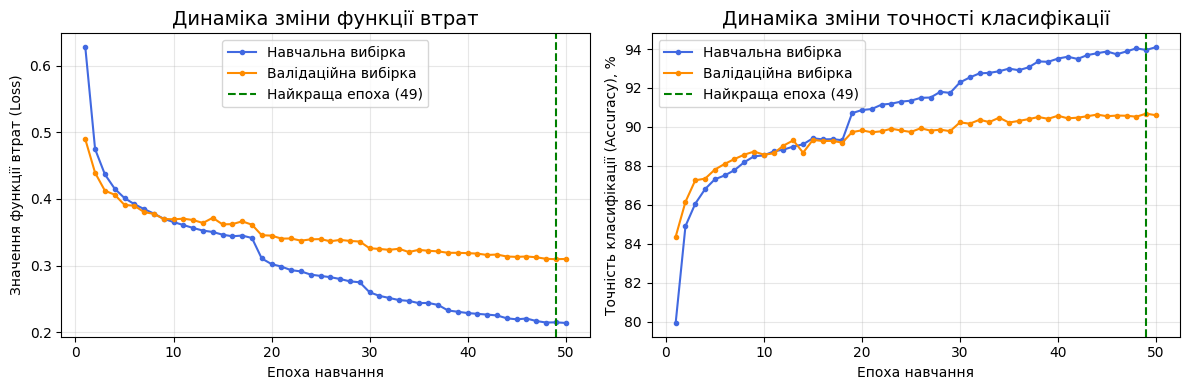

In [30]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:

test_loss_tuner, test_accuracy_tuner = best_model.evaluate(
    x_test_tuner,
    y_test_tuner,
    verbose = 0
)

print("Результати оцінювання моделі з найкращими гіперпараметрами:")
print(f"Значення функції втрат (Loss): {test_loss_tuner:.4f}")
print(f"Точність класифікації (Accuracy): {test_accuracy_tuner:.4f}")
print(f"Точність класифікації у відсотках: {test_accuracy_tuner * 100:.2f}%")

print("\nПорівняння тестової точності моделей:")
print(f"Точність базової моделі: {test_accuracy * 100:.2f}%")
print(f"Точність моделі Keras Tuner: {test_accuracy_tuner * 100:.2f}%")
print(f"Різниця точності: {(test_accuracy_tuner - test_accuracy) * 100:+.2f} в. п.")

train_loss_tuner = history_tuner.history["loss"]
val_loss_tuner = history_tuner.history["val_loss"]

train_accuracy_tuner = np.array(
    history_tuner.history["accuracy"]
) * 100

val_accuracy_tuner = np.array(
    history_tuner.history["val_accuracy"]
) * 100

epochs_range_tuner = range(1, len(train_loss_tuner) + 1)

best_epoch_tuner_plot = np.argmax(val_accuracy_tuner) + 1

plt.figure(figsize = (12, 4))

plt.subplot(1, 2, 1)

plt.plot(epochs_range_tuner, train_loss_tuner,
         color = "royalblue", marker = "o", markersize = 3,
         label = "Навчальна вибірка")

plt.plot(epochs_range_tuner, val_loss_tuner,
         color = "darkorange", marker = "o", markersize = 3,
         label = "Валідаційна вибірка")

plt.axvline(x = best_epoch_tuner_plot,
            color = "green", linestyle = "--",
            label = f"Найкраща епоха ({best_epoch_tuner_plot})")

plt.title("Динаміка зміни функції втрат", fontsize = 14)
plt.xlabel("Епоха навчання")
plt.ylabel("Значення функції втрат (Loss)")
plt.legend()
plt.grid(alpha = 0.3)

plt.subplot(1, 2, 2)

plt.plot(epochs_range_tuner, train_accuracy_tuner,
         color = "royalblue", marker = "o", markersize = 3,
         label = "Навчальна вибірка")

plt.plot(epochs_range_tuner, val_accuracy_tuner,
         color = "darkorange", marker = "o", markersize = 3,
         label = "Валідаційна вибірка")

plt.axvline(x = best_epoch_tuner_plot,
            color = "green", linestyle = "--",
            label = f"Найкраща епоха ({best_epoch_tuner_plot})")

plt.title("Динаміка зміни точності класифікації", fontsize = 14)
plt.xlabel("Епоха навчання")
plt.ylabel("Точність класифікації (Accuracy), %")
plt.legend()
plt.grid(alpha = 0.3)

plt.tight_layout()
plt.show()

###**Пояснення:**

Для оцінювання використано модель `best_model`, вагові коефіцієнти якої відновлено з найкращої, 49-ї епохи навчання. За допомогою методу `best_model.evaluate()` визначено значення функції втрат (`loss`) та точності класифікації (`accuracy`) на тестовій вибірці. Отримані результати збережено у змінних `test_loss_tuner` та `test_accuracy_tuner` відповідно.

На основі отриманих результатів виконано порівняння тестової точності базової нейронної мережі першого завдання та нейронної мережі з гіперпараметрами, підібраними за допомогою `Keras Tuner`.

За результатами порівняння встановлено, що застосування автоматизованого добору гіперпараметрів та повторного навчання обраної конфігурації дозволило підвищити точність класифікації на тестовій вибірці з 89.08% до 89.69%, тобто на 0.61 відсотка. При цьому кількість неправильно класифікованих зображень зменшилася з 1 092 до 1 031.

Незважаючи на підвищення точності класифікації, значення тестової функції втрат збільшилося з 0.3255 до 0.3433. Однак необхідно враховувати, що в моделі другого завдання застосовано регуляризацію `L2`, штраф за яку додатково включено до загального значення функції втрат. Тому безпосереднє порівняння значень функцій втрат обох моделей не є цілком коректним.

**Аналіз графіків навчання нейронної мережі**

На основі збереженої історії навчання нейронної мережі (`history_tuner`) за допомогою бібліотеки Matplotlib побудовано два графіки, які відображають динаміку зміни значень функції втрат та точності класифікації на навчальній і валідаційній вибірках протягом 50 епох навчання.

З історії навчання отримано значення таких показників:

- `loss` — значення функції втрат на навчальній вибірці;

- `val_loss` — значення функції втрат на валідаційній вибірці;

- `accuracy` — точність класифікації на навчальній вибірці;

- `val_accuracy` — точність класифікації на валідаційній вибірці.

Для більш наочного представлення результатів значення точності класифікації переведено у відсотки. На обох графіках синім кольором позначено показники навчальної вибірки, помаранчевим — показники валідаційної вибірки, а зеленою вертикальною пунктирною лінією — найкращу епоху навчання (49-ту), визначену за максимальним значенням валідаційної точності (`val_accuracy`).

**Аналіз графіка динаміки зміни функції втрат (`Loss`).**

На першому графіку спостерігається загальне зменшення значень функції втрат на навчальній та валідаційній вибірках протягом усього процесу навчання. Найбільш інтенсивне зменшення відбувається протягом перших епох, що свідчить про ефективне засвоєння нейронною мережею основних закономірностей у вхідних даних.

Значення функції втрат на навчальній вибірці зменшилося з 0.6279 на першій епосі до 0.2139 на останній. На валідаційній вибірці значення функції втрат зменшилося з 0.4896 до мінімального значення 0.3096, отриманого на 49-й епосі.

Починаючи приблизно з 10-ї епохи, спостерігається поступове збільшення розбіжності між кривими навчальної та валідаційної вибірок. Особливо помітне зменшення значень функції втрат на навчальній вибірці відбувається після 18-ї та 29-ї епох, на яких спрацювала `callback`-функція `ReduceLROnPlateau` та було зменшено швидкість навчання.

На завершальних етапах навчання значення функції втрат на навчальній вибірці продовжує зменшуватися інтенсивніше, ніж на валідаційній. Збільшення розбіжності між кривими свідчить про наявність певних ознак перенавчання нейронної мережі. Водночас валідаційна функція втрат продовжує загалом зменшуватися майже до завершення навчання, тому вираженого погіршення якості моделі на валідаційній вибірці не спостерігається.

**Аналіз графіка динаміки зміни точності класифікації (`Accuracy`).**

На другому графіку спостерігається поступове зростання точності класифікації на навчальній та валідаційній вибірках. Найбільш інтенсивне зростання точності відбувається протягом перших епох навчання, після чого темп покращення показників поступово зменшується.

На початкових епохах точність на валідаційній вибірці перевищує точність на навчальній вибірці. Однією з причин цього є застосування регуляризації `Dropout`, яка активна під час навчання нейронної мережі, але не використовується під час валідації.

Протягом перших 15 епох значення навчальної та валідаційної точності поступово зближуються. Починаючи приблизно з 19-ї епохи, спостерігається більш виражене зростання точності на навчальній вибірці та поступове збільшення розбіжності між кривими.

Наприкінці навчання точність на навчальній вибірці досягає 94.10%, тоді як точність на валідаційній вибірці стабілізується на рівні близько 90–91%. Максимальне значення валідаційної точності 90.68% отримано на 49-й епосі.

Розбіжність між показниками навчальної та валідаційної точності на найкращій епосі становить 3.27 відсотка, а на останній — 3.50 відсотка. Отримані результати свідчать про наявність певних ознак перенавчання на завершальному етапі навчання, незважаючи на одночасне застосування регуляризації `Dropout` та `L2`.

Застосування `callback`-функції `ReduceLROnPlateau` забезпечило п’ятиразове зменшення швидкості навчання. Дострокового припинення навчання за допомогою `EarlyStopping` не відбулося, тому виконано всі 50 запланованих епох. Після завершення навчання завдяки параметру `restore_best_weights = True` відновлено вагові коефіцієнти, отримані на 49-й епосі, для якої зафіксовано максимальне значення валідаційної точності.

Розбіжність між точністю класифікації на валідаційній та тестовій вибірках становить 0.99 відсотка. Незважаючи на виявлені ознаки перенавчання, отримані результати свідчать про достатньо хорошу узагальнювальну здатність нейронної мережі та її здатність класифікувати зображення, які не використовувалися під час навчання.


# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 3 | 1 |
| Кількість нейронів | 256, 128, 64	 | 512 |
| Швидкість навчання | 0.001 | 0.001 |
| Точність на тестовій вибірці (accuracy) | 0.8908 (89.08%)	 | 0.8969 (89.69%) |
| Втрати на тестовій вибірці (loss) | 0.3255 | 0.3433 |
| Кількість епох навчання | 29 | 50 |

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
_..._

###**Підсумкові висновки:**

**1) Чи досягнуто точності не нижче 0,87 у завданні 1?**

За результатами фінального оцінювання базової нейронної мережі на незалежній тестовій вибірці набору даних `Fashion MNIST` отримано точність класифікації 0.8908 (89.08%) та значення функції втрат 0.3255. Нейронна мережа правильно класифікувала 8 908 із 10 000 тестових зображень. Отримана точність перевищує встановлене умовою завдання мінімальне порогове значення 87% на 2.08 відсотка. Отже, вимогу щодо мінімальної точності класифікації у першому завданні виконано.

**2) Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?**

Застосування автоматизованого добору гіперпараметрів за допомогою алгоритму `RandomSearch` бібліотеки `Keras Tuner` та повторне навчання обраної конфігурації дозволили підвищити точність класифікації на тестовій вибірці з 89.08% до 89.69%, тобто на 0.61 відсотка. При цьому кількість правильно класифікованих зображень збільшилася з 8 908 до 8 969, а кількість помилкових прогнозів зменшилася з 1 092 до 1 031.

Водночас значення тестової функції втрат збільшилося з 0.3255 до 0.3433. Безпосереднє порівняння цих значень не є цілком коректним, оскільки в моделі другого завдання до функції втрат додатково включено штраф за регуляризацію `L2`.

Покращення точності класифікації супроводжувалося збільшенням кількості навчуваних параметрів нейронної мережі з 242 762 до 407 050 (приблизно на 67.68%), а також збільшенням кількості епох навчання з 29 до 50. Крім того, розбіжність між навчальною та валідаційною точністю на найкращій епосі збільшилася з 1.21 до 3.27 відсотка, що свідчить про більш виражені ознаки перенавчання другої моделі.

Отже, у межах проведеного експерименту автоматизований добір гіперпараметрів забезпечив незначне покращення тестової точності, проте ціною збільшення обчислювальної складності моделі. Оскільки також відрізнялися параметри регуляризації, тривалість навчання та критерії вибору найкращої епохи, весь отриманий приріст точності не можна однозначно пояснити лише застосуванням `Keras Tuner`.

**3) Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?**

У результаті автоматизованого пошуку гіперпараметрів за допомогою алгоритму `RandomSearch` досліджено три різні конфігурації нейронної мережі, для яких отримано валідаційну точність 82.81%, 89.85% та 90.47% відповідно.

Найкращою серед досліджених виявилася конфігурація з такими характеристиками:

- кількість прихованих повнозв’язних шарів — 1;

- кількість нейронів прихованого шару — 512;

- початкова швидкість навчання — 0.001;

- функція активації прихованого шару — `ReLU`;

- коефіцієнт `Dropout` — 0.3 (фіксований параметр);

- коефіцієнт регуляризації `L2` — 0.0001 (фіксований параметр);

- оптимізатор — `Adam`;

- функція активації вихідного шару — `softmax`.

Під час автоматизованого пошуку ця конфігурація забезпечила валідаційну точність 90.47%, а після повторного навчання — 90.68%.

Отримані результати продемонстрували, що збільшення кількості прихованих шарів не обов’язково забезпечує покращення якості класифікації. У проведеному експерименті нейронна мережа з одним прихованим шаром і більшою кількістю нейронів забезпечила вищу точність, ніж досліджені багатошарові конфігурації.

Результати пошуку та навчання нейронної мережі можуть відрізнятися між запусками внаслідок випадкового вибору комбінацій гіперпараметрів алгоритмом `RandomSearch`, випадкової ініціалізації вагових коефіцієнтів, перемішування навчальних даних, застосування регуляризації `Dropout`, а також особливостей виконання обчислень на різних обчислювальних пристроях (CPU та GPU).

Також необхідно враховувати, що із 13 104 можливих комбінацій гіперпараметрів досліджено лише три, тому знайдена конфігурація є найкращою серед перевірених, але не обов’язково глобально оптимальною.

**4) Які класи `Fashion MNIST` класифікувати найскладніше?**

За результатами аналізу класифікаційного звіту базової нейронної мережі встановлено, що найбільші труднощі виникли під час розпізнавання таких класів:


| Клас | Precision | Recall | F1-score | Кількість нерозпізнаних зображень класу |
|---|---:|---:|---:|---:|
| Сорочка | 0.7418 | 0.6810 | 0.7101 | 319 |
| Пальто | 0.8114 | 0.7960 | 0.8036 | 204 |
| Пуловер | 0.7838 | 0.8300 | 0.8062 | 170 |
| Футболка / топ | 0.8256 | 0.8570 | 0.8410 | 143 |

Найскладнішим для класифікації виявився клас «Сорочка», для якого отримано найнижчі значення `Recall` (0.6810) та `F1-score` (0.7101). Нейронна мережа правильно розпізнала лише 681 із 1000 зображень цього класу.

Можливою причиною виникнення помилок є візуальна схожість предметів верхнього одягу за формою, контурами, довжиною рукавів та іншими характеристиками. Крім того, низька роздільна здатність зображень (28 × 28 пікселів) та відсутність інформації про колір ускладнюють розпізнавання дрібних відмінностей між предметами одягу.

Найкращі результати класифікації за метрикою `F1-score` отримано для класів «Штани» (0.9789), «Сумка» (0.9764), «Сандалі» (0.9742), «Ботильйони» (0.9624) та «Кросівки» (0.9552), які мають більш характерні візуальні ознаки.

Отже, якість класифікації залежить не лише від архітектури нейронної мережі та її гіперпараметрів, але й від особливостей вхідних зображень і ступеня візуальної схожості між класами.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.